Dataset shape: (569, 30)
Features: ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']
Classes: ['malignant' 'benign']

Test accuracy: 36.84%

Classification report:
              precision    recall  f1-score   support

   malignant       0.37      1.00      0.54        42
      benign       0.00      0.00      0.00        72

    accuracy                           0.37       114
   macro avg       0.18      0.50      0.27       114
weighted avg       0.14      0.37      0.20       114



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


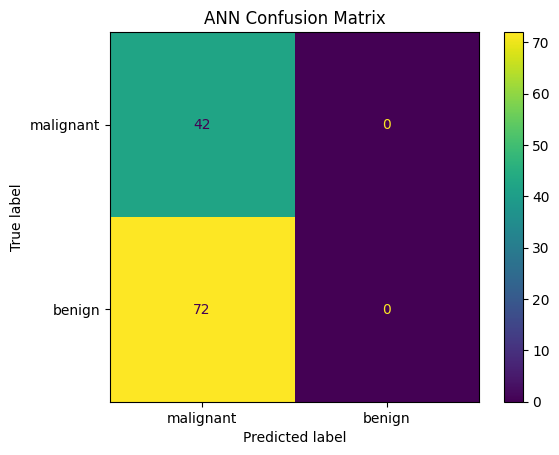

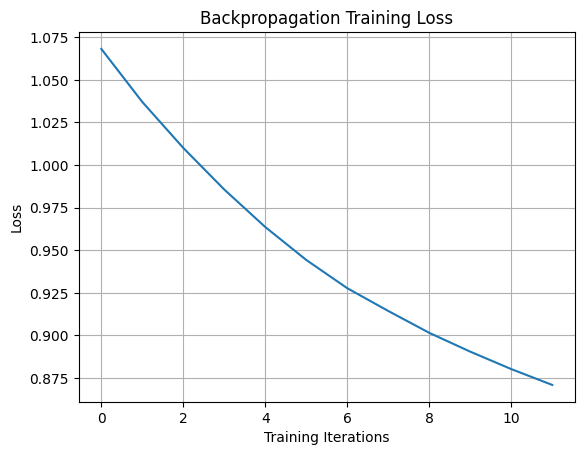

Predicted class: malignant
Actual class: malignant


In [2]:

# EXPERIMENT 4: ANN USING BACKPROPAGATION
# Run this cell in Google Colab

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

# Step 1: Load the dataset
dataset = load_breast_cancer()

X = dataset.data
y = dataset.target

print("Dataset shape:", X.shape)
print("Features:", dataset.feature_names[:5])
print("Classes:", dataset.target_names)

# Step 2: Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Step 3: Standardize the input data
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 4: Build and train ANN using backpropagation
ann = MLPClassifier(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=42,
    early_stopping=True
)

ann.fit(X_train, y_train)

# Step 5: Predict test samples
y_pred = ann.predict(X_test)

# Step 6: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print(f"\nTest accuracy: {accuracy * 100:.2f}%")
print("\nClassification report:")
print(classification_report(
    y_test, y_pred,
    target_names=dataset.target_names
))

# Step 7: Plot the confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=dataset.target_names
)
plt.title("ANN Confusion Matrix")
plt.show()

# Step 8: Plot training loss
plt.plot(ann.loss_curve_)
plt.xlabel("Training Iterations")
plt.ylabel("Loss")
plt.title("Backpropagation Training Loss")
plt.grid(True)
plt.show()

# Step 9: Predict one new test sample
sample = X_test[0].reshape(1, -1)
predicted_class = ann.predict(sample)[0]

print("Predicted class:",
      dataset.target_names[predicted_class])
print("Actual class:",
      dataset.target_names[y_test[0]])
